In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import models, layers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

In [ ]:
# ==========================================
# 1. Data Preparation
# ==========================================
num_notes = 50         # vocabulary size (distinct notes)
sequence_length = 30   # notes per stored sequence
num_sequences = 1000   # how many sequences in the toy dataset

np.random.seed(42)
data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))

x_train = data[:, :-1]  # notes 0..28 -> input
y_train = data[:, 1:]   # notes 1..29 -> target (shifted by one)

x_train = to_categorical(x_train, num_classes=num_notes)  # (1000, 29, 50)
y_train = to_categorical(y_train, num_classes=num_notes)  # (1000, 29, 50)

In [ ]:
# ==========================================
# 2. Model Definition
# ==========================================
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length - 1, num_notes)))  # (29, 50)
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # -> (29, 256)
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # -> (29, 256)
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # -> (29, 50)

In [ ]:
# ==========================================
# 3. Compile and Train
# ==========================================
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.0832 - loss: 3.8835 - val_accuracy: 0.1141 - val_loss: 3.8421
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.1103 - loss: 3.7677 - val_accuracy: 0.0933 - val_loss: 3.6544
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1236 - loss: 3.5098 - val_accuracy: 0.1386 - val_loss: 3.3984
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1657 - loss: 3.2187 - val_accuracy: 0.1834 - val_loss: 3.0992
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2120 - loss: 2.8848 - val_accuracy: 0.2398 - val_loss: 2.7398
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.2741 - loss: 2.5035 - val_accuracy: 0.3119 - val_loss: 2.3444
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3463 - loss: 2.1220 - val_accuracy: 0.3840 - val_loss: 1.9764
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4292 - loss: 1.7528 - val_accuracy: 0.4734 - v

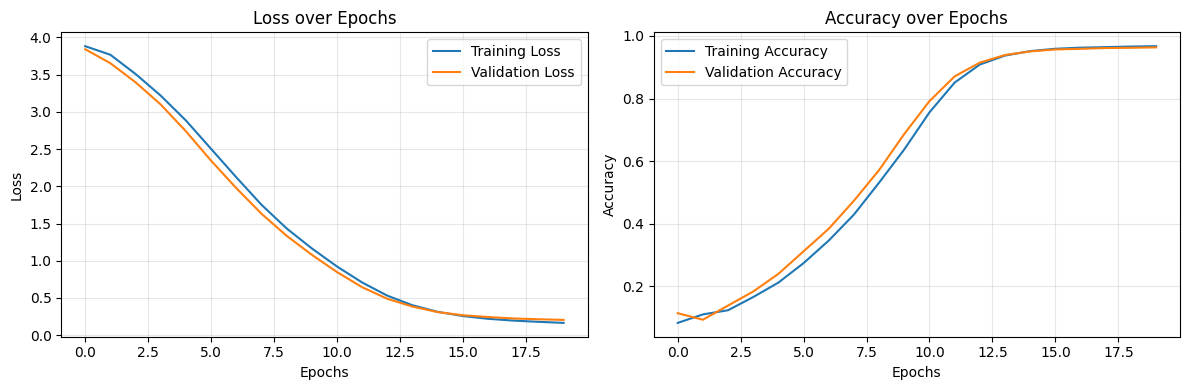

In [ ]:
# ==========================================
# 4. Visualise Training History (Figure 5.1)
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss plot
ax1.plot(history.history['loss'], label='Training Loss')
ax1.plot(history.history['val_loss'], label='Validation Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy plot
ax2.plot(history.history['accuracy'], label='Training Accuracy')
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 5. Autoregressive Music Generation
# ==========================================
def generate_music(model, start_sequence, num_generated_notes=50):
    generated, current = [], start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current, verbose=0)                # (1, 29, 50)
        next_note = np.argmax(pred[:, -1, :], axis=-1)          # read LAST step
        generated.append(int(next_note[0]))
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current = np.concatenate([current[:, 1:, :], oh], axis=1)  # slide window
    return generated

# Pick the first sample as the seed window: shape (1, 29, 50)
seed_sequence = x_train[0:1]
generated_notes = generate_music(model, seed_sequence, num_generated_notes=50)
print("Generated sequence (greedy):", generated_notes)

Generated sequence (greedy): [24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24]


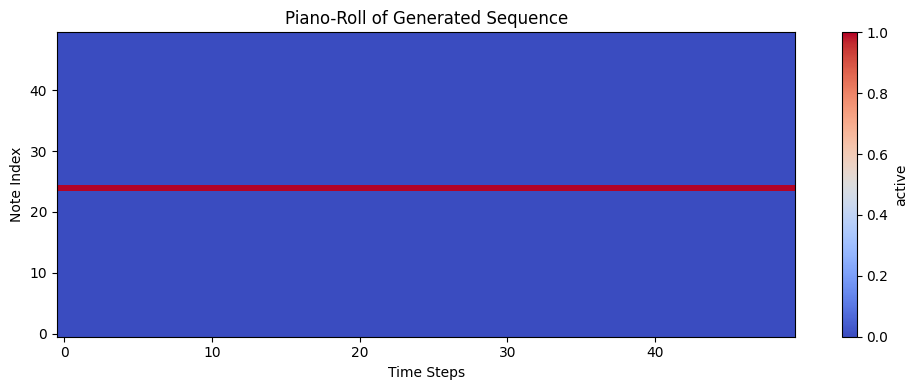

In [ ]:
# ==========================================
# 6. Visualise Piano-Roll (Figure 5.2)
# ==========================================
piano_roll = np.zeros((num_notes, len(generated_notes)))
for step, note in enumerate(generated_notes):
    piano_roll[note, step] = 1.0

plt.figure(figsize=(10, 4))
plt.imshow(piano_roll, aspect='auto', origin='lower', cmap='coolwarm')
plt.colorbar(label='active')
plt.title('Piano-Roll of Generated Sequence')
plt.xlabel('Time Steps')
plt.ylabel('Note Index')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from IPython.display import Audio, display

sample_rate = 22050
note_duration = 0.25  # seconds per note
t = np.linspace(0, note_duration, int(sample_rate * note_duration), endpoint=False)

# Fade-out envelope so each note sounds like a struck key instead of a continuous buzz
envelope = np.exp(-6 * t)

audio_wave = np.array([])
for note in generated_notes:
    # Convert note index (0..39) to MIDI pitch (48 = C3) and frequency in Hz
    freq = 440.0 * (2.0 ** ((note + 48 - 69) / 12.0))
    tone = (0.7 * np.sin(2 * np.pi * freq * t) + 0.3 * np.sin(2 * np.pi * 2 * freq * t)) * envelope
    audio_wave = np.concatenate([audio_wave, tone])

# Display the playable audio player in Colab (click the Play ▶ button)
display(Audio(audio_wave, rate=sample_rate))